# Figure 2: Private reputation and directional inertia

Run from this notebook directory, top to bottom. The notebook works in four steps:

1. **Model**: simulation kernels and run settings.
2. **Generate and save data**: simulates the 12 reputation matrices and the 196-condition depth scan and writes them to `data/figure2/`.
3. **Load the saved data**: reads everything back from `data/figure2/` and checks it, so the figures are always made from the files on disk.
4. **Plot and save figures**: writes PDF and SVG files to `figures/figure2/`.

`RECOMPUTE_MATRICES` and `RECOMPUTE_DEPTH_SCAN` (next cell) control step 2. With both set to `True` (default), the full pipeline runs; a full regeneration takes about 4 minutes, almost all of it in the depth scan (measured on a cloud machine). Set either flag to `False` to skip that simulation and plot the data already saved in `data/figure2/`. Requires NumPy, pandas, Matplotlib, Numba, and IPython.

**Outputs**

- Data (`data/figure2/`): `{norm}_{regime}.npz` and `snapshot_config.json` for the matrices; `path_length_plane_raw.csv`, `path_length_plane_summary.csv` and `path_length_plane_config.json` for the depth scan.
- Figures (`figures/figure2/`): `Figure2_combined`, the assembled figure at the final double-column width (183 mm); `matrix_*`, `depth_*` and `key_*`, single panels and key elements for manual assembly. These contain no text or numbers (depth panels keep their tick marks), and each is drawn at exactly the size it has in the combined figure, so it can be placed at 100% scale.

## Step 1: Model

Run settings and simulation kernels. Records use direct-reset transitions. A positive assessment clears any warning; a negative assessment clears any recovery state. Binary readout is sampled independently whenever a record is consulted. DISC observers are sampled independently of donor and recipient; self-images are retained.

In [1]:
from pathlib import Path
from typing import Tuple
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Rectangle, Patch, FancyBboxPatch
from matplotlib.transforms import Affine2D
from matplotlib.lines import Line2D
from numba import njit
from IPython.display import display

ROOT = Path.cwd()
DATA = ROOT / "data" / "figure2"
FIGURES = ROOT / "figures" / "figure2"
DATA.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
RECOMPUTE_MATRICES = True
RECOMPUTE_DEPTH_SCAN = True

NORMS = ("SC", "SH", "SJ", "SS")
NORM_PARAMETERS = {"SC": (1., 0.), "SH": (0., 0.), "SJ": (0., 1.), "SS": (1., 1.)}
NORM_NAMES = {"SC": "Scoring", "SH": "Shunning", "SJ": "Stern Judging", "SS": "Simple Standing"}
TARGETS = ("DISC", "ALLC", "ALLD")
REGIMES = ("without_inertia", "one_step", "multi_step")
REGIME_NAMES = {"without_inertia": "Without inertia", "one_step": "One-step inertia", "multi_step": "Multi-step inertia"}
MULTISTEP_DEPTHS = {"SC": (2, 0), "SH": (3, 0), "SJ": (4, 3), "SS": (1, 2)}
MATRIX_PARAMETERS = dict(n_disc=30, n_allc=30, n_alld=30, e1=.02, e2=.02, sweeps=1000, seed=2027)
DEPTH_PARAMETERS = dict(norms=list(NORMS), tolerance_depths=list(range(7)), strictness_depths=list(range(7)),
    n_disc=50, n_allc=50, n_alld=50, e1=.02, e2=.02, sweeps_total=1000., sweeps_burnin=800.,
    sample_interval_sweeps=5., n_reps=1, seed=2027)
METRICS = ("g_DISC", "g_ALLC", "g_ALLD", "disagreement_DISC", "disagreement_ALLC", "disagreement_ALLD", "warning_fraction", "suspicious_fraction")
SUMMARY_METRICS = METRICS + ("mean_disagreement", "cooperator_defector_separation", "intermediate_fraction")


In [2]:
def build_sigma(alpha: float, beta: float, k1: int, k2: int) -> np.ndarray:
    sigma = np.empty(2 + k1 + k2, dtype=np.float64)
    sigma[0] = 1.0
    for m in range(1, k1 + 1):
        sigma[m] = alpha ** m
    b_index = k1 + 1
    sigma[b_index] = 0.0
    for n in range(1, k2 + 1):
        sigma[b_index + n] = 1.0 - beta ** n
    return sigma

def build_reset_transitions(k1: int, k2: int) -> Tuple[np.ndarray, np.ndarray]:
    n_states = 2 + k1 + k2
    b_index = k1 + 1
    positive = np.empty(n_states, dtype=np.int16)
    negative = np.empty(n_states, dtype=np.int16)
    positive[0] = 0
    negative[0] = 1 if k1 > 0 else b_index
    for m in range(1, k1 + 1):
        positive[m] = 0
        negative[m] = m + 1 if m < k1 else b_index
    positive[b_index] = b_index + 1 if k2 > 0 else 0
    negative[b_index] = b_index
    for n in range(1, k2 + 1):
        state = b_index + n
        positive[state] = state + 1 if n < k2 else 0
        negative[state] = b_index
    return (positive, negative)

@njit(cache=False)
def _simulate_condition(n_disc: int, n_allc: int, n_alld: int, p_norm: float, q_norm: float, e1: float, e2: float, sigma: np.ndarray, positive: np.ndarray, negative: np.ndarray, n_events: int, use_seed: bool, seed: int) -> np.ndarray:
    if use_seed:
        np.random.seed(seed)
    population_size = n_disc + n_allc + n_alld
    latent = np.zeros((n_disc, population_size), dtype=np.int16)
    for _ in range(n_events):
        donor = np.random.randint(0, population_size)
        recipient = np.random.randint(0, population_size - 1)
        if recipient >= donor:
            recipient += 1
        observer = np.random.randint(0, n_disc)
        if donor < n_disc:
            intended_cooperation = int(np.random.random() < sigma[latent[donor, recipient]])
        elif donor < n_disc + n_allc:
            intended_cooperation = 1
        else:
            intended_cooperation = 0
        if intended_cooperation == 1:
            realized_cooperation = int(np.random.random() >= e1)
        else:
            realized_cooperation = 0
        recipient_good = int(np.random.random() < sigma[latent[observer, recipient]])
        if realized_cooperation == 1:
            positive_probability = 1.0 if recipient_good == 1 else p_norm
        else:
            positive_probability = 0.0 if recipient_good == 1 else q_norm
        recorded_positive = int(np.random.random() < positive_probability)
        if np.random.random() < e2:
            recorded_positive = 1 - recorded_positive
        current = latent[observer, donor]
        latent[observer, donor] = positive[current] if recorded_positive == 1 else negative[current]
    return latent

@njit(cache=False)
def _binary_draw(probability: float) -> int:
    return 1 if np.random.random() < probability else 0

@njit(cache=False)
def _accumulate_statistics(latent: np.ndarray, sigma: np.ndarray, n_disc: int, n_allc: int, k1: int, accumulator: np.ndarray) -> None:
    population_size = latent.shape[1]
    starts = (0, n_disc, n_disc + n_allc)
    ends = (n_disc, n_disc + n_allc, population_size)
    for group in range(3):
        sum_target_goodness = 0.0
        sum_target_disagreement = 0.0
        n_targets = ends[group] - starts[group]
        for target in range(starts[group], ends[group]):
            sum_s = 0.0
            sum_s2 = 0.0
            for observer in range(n_disc):
                value = sigma[latent[observer, target]]
                sum_s += value
                sum_s2 += value * value
            sum_target_goodness += sum_s / n_disc
            numerator = (n_disc - 1.0) * sum_s - (sum_s * sum_s - sum_s2)
            denominator = 0.5 * n_disc * (n_disc - 1.0)
            sum_target_disagreement += numerator / denominator
        accumulator[group] += sum_target_goodness / n_targets
        accumulator[3 + group] += sum_target_disagreement / n_targets
    b_index = k1 + 1
    warning_count = 0
    suspicious_count = 0
    for observer in range(latent.shape[0]):
        for target in range(latent.shape[1]):
            state = latent[observer, target]
            if 1 <= state < b_index:
                warning_count += 1
            elif state > b_index:
                suspicious_count += 1
    n_records = latent.shape[0] * latent.shape[1]
    accumulator[6] += warning_count / n_records
    accumulator[7] += suspicious_count / n_records

@njit(cache=False)
def _simulate_replicate(n_disc: int, n_allc: int, n_alld: int, p_norm: float, q_norm: float, e1: float, e2: float, k1: int, sigma: np.ndarray, positive: np.ndarray, negative: np.ndarray, total_events: int, burnin_events: int, interval_events: int, use_seed: bool, seed: int) -> Tuple[np.ndarray, int]:
    if use_seed:
        np.random.seed(seed)
    population_size = n_disc + n_allc + n_alld
    latent = np.zeros((n_disc, population_size), dtype=np.int16)
    accumulator = np.zeros(8, dtype=np.float64)
    n_samples = 0
    next_sample = burnin_events
    for event in range(total_events):
        donor = np.random.randint(0, population_size)
        recipient = np.random.randint(0, population_size - 1)
        if recipient >= donor:
            recipient += 1
        observer = np.random.randint(0, n_disc)
        if donor < n_disc:
            intended_cooperation = _binary_draw(sigma[latent[donor, recipient]])
        elif donor < n_disc + n_allc:
            intended_cooperation = 1
        else:
            intended_cooperation = 0
        realized_cooperation = intended_cooperation
        if intended_cooperation == 1 and np.random.random() < e1:
            realized_cooperation = 0
        recipient_good = _binary_draw(sigma[latent[observer, recipient]])
        if realized_cooperation == 1:
            positive_probability = 1.0 if recipient_good == 1 else p_norm
        else:
            positive_probability = 0.0 if recipient_good == 1 else q_norm
        recorded_positive = _binary_draw(positive_probability)
        if np.random.random() < e2:
            recorded_positive = 1 - recorded_positive
        current = latent[observer, donor]
        latent[observer, donor] = positive[current] if recorded_positive == 1 else negative[current]
        completed_events = event + 1
        if completed_events >= next_sample:
            _accumulate_statistics(latent, sigma, n_disc, n_allc, k1, accumulator)
            n_samples += 1
            next_sample += interval_events
    if n_samples > 0:
        accumulator /= n_samples
    return (accumulator, n_samples)

In [3]:
def snapshot_parameters(norm, regime):
    parameters = dict(MATRIX_PARAMETERS, norm=norm, regime=regime)
    k1, k2 = MULTISTEP_DEPTHS[norm] if regime == "multi_step" else (1, 1)
    parameters.update(k1=k1, k2=k2, alpha=0. if regime == "without_inertia" else 1.,
                      beta=0. if regime == "without_inertia" else 1.)
    return parameters


def simulate_snapshot(parameters):
    p = parameters
    sigma = build_sigma(p["alpha"], p["beta"], p["k1"], p["k2"])
    positive, negative = build_reset_transitions(p["k1"], p["k2"])
    n_records = p["n_disc"] * (p["n_disc"] + p["n_allc"] + p["n_alld"])
    latent = _simulate_condition(p["n_disc"], p["n_allc"], p["n_alld"], *NORM_PARAMETERS[p["norm"]],
        p["e1"], p["e2"], sigma, positive, negative, int(round(p["sweeps"] * n_records)), True, p["seed"])
    return latent, sigma[latent]


def save_figure(figure, name, tight=True):
    for extension, metadata in (("pdf", {"CreationDate": None}), ("svg", {"Date": None})):
        figure.savefig(FIGURES / f"{name}.{extension}", dpi=EXPORT_DPI, metadata=metadata,
                       bbox_inches="tight" if tight else None, pad_inches=.04 if tight else 0.)


for k1 in range(7):
    for k2 in range(7):
        positive, negative = build_reset_transitions(k1, k2)
        bad = k1 + 1
        assert np.all(positive[1:bad] == 0)
        assert np.all(negative[bad + 1:] == bad)
        state = 0
        for _ in range(k1 + 1):
            state = negative[state]
        assert state == bad
        for _ in range(k2 + 1):
            state = positive[state]
        assert state == 0


In [4]:
def summarize_depth(raw):
    rows = []
    for key, group in raw.groupby(["norm", "norm_name", "k1", "k2"], sort=False):
        row = dict(zip(("norm", "norm_name", "k1", "k2"), key))
        row["n_reps"] = len(group)
        for metric in SUMMARY_METRICS:
            values = group[metric].to_numpy(float)
            row[f"{metric}_mean"] = values.mean()
            row[f"{metric}_sd"] = values.std(ddof=1) if len(values) > 1 else np.nan
            row[f"{metric}_sem"] = row[f"{metric}_sd"] / np.sqrt(len(values))
        rows.append(row)
    return pd.DataFrame(rows)


def simulate_depth_scan(parameters):
    p = parameters
    n_records = p["n_disc"] * (p["n_disc"] + p["n_allc"] + p["n_alld"])
    total = int(round(p["sweeps_total"] * n_records))
    burnin = int(round(p["sweeps_burnin"] * n_records))
    interval = int(round(p["sample_interval_sweeps"] * n_records))
    assert 0 <= burnin < total and interval > 0 and p["n_reps"] > 0
    rows = []
    for norm in p["norms"]:
        for k2 in p["strictness_depths"]:
            for k1 in p["tolerance_depths"]:
                sigma = build_sigma(1., 1., k1, k2)
                positive, negative = build_reset_transitions(k1, k2)
                for replicate in range(p["n_reps"]):
                    seed = int(np.random.SeedSequence([p["seed"], NORMS.index(norm), k1, k2, replicate]).generate_state(1, dtype=np.uint32)[0])
                    values, n_samples = _simulate_replicate(p["n_disc"], p["n_allc"], p["n_alld"],
                        *NORM_PARAMETERS[norm], p["e1"], p["e2"], k1, sigma, positive, negative,
                        total, burnin, interval, True, seed)
                    row = dict(norm=norm, norm_name=NORM_NAMES[norm], k1=k1, k2=k2,
                        tolerance_path_length=k1 + 1, strictness_path_length=k2 + 1,
                        replicate=replicate, transition_rule="direct_reset")
                    row.update(dict(zip(METRICS, values)))
                    row.update(mean_disagreement=np.average(values[3:6], weights=[p["n_disc"], p["n_allc"], p["n_alld"]]),
                        cooperator_defector_separation=.5 * (values[0] + values[1]) - values[2],
                        intermediate_fraction=values[6] + values[7], n_samples=n_samples, simulation_seed=seed)
                    rows.append(row)
        print(f"Completed {norm} depth scan.")
    return pd.DataFrame(rows)


## Step 2: Generate and save data

**Reputation matrices.** The three target blocks are DISC, ALLC, and ALLD. Each snapshot uses 30 individuals per strategy, 1,000 sweeps, and seed 2027. The multi-step depths are SC (2,0), SH (3,0), SJ (4,3), and SS (1,2). Without inertia uses $\alpha=\beta=0$; one-step and multi-step inertia use $\alpha=\beta=1$.

**Depth plane.** The scan uses full readout ($\alpha=\beta=1$), 50 individuals per strategy, depths 0-6, one replicate per condition, and seed 2027. Sampling covers sweeps 800-1,000 every five sweeps. Each condition records separation $\Delta g=(g_{\mathrm{DISC}}+g_{\mathrm{ALLC}})/2-g_{\mathrm{ALLD}}$ and observer disagreement $\bar d$.

Both simulations overwrite the files in `data/figure2/`; the supplied versions remain in the repository history.

In [5]:
matrix_configuration = [snapshot_parameters(norm, regime) for norm in NORMS for regime in REGIMES]
configuration_file = DATA / "snapshot_config.json"
if RECOMPUTE_MATRICES:
    for parameters in matrix_configuration:
        latent, expressed = simulate_snapshot(parameters)
        np.savez_compressed(DATA / f"{parameters['norm']}_{parameters['regime']}.npz", latent=latent, expressed=expressed)
    configuration_file.write_text(json.dumps(matrix_configuration, indent=2))
    print(f"Generated and saved {len(matrix_configuration)} reputation matrices in {DATA.relative_to(ROOT)}.")
else:
    print("RECOMPUTE_MATRICES=False: using the matrices already saved in data/figure2.")


Generated and saved 12 reputation matrices in data/figure2.


In [6]:
raw_file = DATA / "path_length_plane_raw.csv"
summary_file = DATA / "path_length_plane_summary.csv"
config_file = DATA / "path_length_plane_config.json"
if RECOMPUTE_DEPTH_SCAN:
    depth_raw = simulate_depth_scan(DEPTH_PARAMETERS)
    depth_summary = summarize_depth(depth_raw)
    depth_raw.to_csv(raw_file, index=False)
    depth_summary.to_csv(summary_file, index=False)
    config_file.write_text(json.dumps(DEPTH_PARAMETERS, indent=2))
    print(f"Generated and saved {len(depth_raw)} depth-scan replicates in {DATA.relative_to(ROOT)}.")
else:
    print("RECOMPUTE_DEPTH_SCAN=False: using the depth scan already saved in data/figure2.")


Completed SC depth scan.


Completed SH depth scan.


Completed SJ depth scan.


Completed SS depth scan.
Generated and saved 196 depth-scan replicates in data/figure2.


## Step 3: Load the saved data

Everything plotted below is read back from `data/figure2/`. The saved run settings must match the parameters in this notebook, and missing or inconsistent files raise an error.

In [7]:
# Matrices
if not configuration_file.is_file():
    raise FileNotFoundError("Snapshot data are missing. Supply data/figure2 or set RECOMPUTE_MATRICES=True.")
if json.loads(configuration_file.read_text()) != matrix_configuration:
    raise ValueError("Snapshot parameters differ from saved data. Set RECOMPUTE_MATRICES=True to regenerate.")
matrices = {}
for parameters in matrix_configuration:
    key = (parameters["norm"], parameters["regime"])
    with np.load(DATA / f"{key[0]}_{key[1]}.npz") as saved:
        latent = saved["latent"]
        expressed = saved["expressed"]
    expected_shape = (parameters["n_disc"], sum(parameters[name] for name in ("n_disc", "n_allc", "n_alld")))
    assert latent.shape == expressed.shape == expected_shape
    assert np.array_equal(expressed, build_sigma(parameters["alpha"], parameters["beta"], parameters["k1"], parameters["k2"])[latent])
    matrices[key] = expressed
print("Loaded 12 reputation matrices.")

# Depth scan
if not all(path.is_file() for path in (raw_file, summary_file, config_file)):
    raise FileNotFoundError("Depth-scan data are missing. Supply data/figure2 or set RECOMPUTE_DEPTH_SCAN=True.")
saved_parameters = json.loads(config_file.read_text())
if any(saved_parameters.get(key) != value for key, value in DEPTH_PARAMETERS.items()):
    raise ValueError("Depth parameters differ from saved data. Set RECOMPUTE_DEPTH_SCAN=True to regenerate.")
depth_raw = pd.read_csv(raw_file)
depth_summary = pd.read_csv(summary_file)
expected_conditions = len(DEPTH_PARAMETERS["norms"]) * len(DEPTH_PARAMETERS["tolerance_depths"]) * len(DEPTH_PARAMETERS["strictness_depths"])
assert len(depth_summary) == expected_conditions
assert len(depth_raw) == expected_conditions * DEPTH_PARAMETERS["n_reps"]
assert (depth_summary["n_reps"] == DEPTH_PARAMETERS["n_reps"]).all()
assert not depth_summary.duplicated(["norm", "k1", "k2"]).any()
print(f"Loaded {len(depth_raw)} depth-scan replicates and {len(depth_summary)} conditions.")


Loaded 12 reputation matrices.
Loaded 196 depth-scan replicates and 196 conditions.


## Step 4: Plot and save figures

**Figure style.** Shared style for all figures in the paper (Scheme A): Arial/Helvetica (Liberation Sans as a metric-compatible fallback), 7 pt labels, 6 pt ticks, 8 pt bold panel letters, 0.5 pt axes, and no top or right spines. Good reputation uses the shared navy ramp, separation $\Delta g$ uses rose-neutral-navy (its positive half follows the navy ramp, so $\Delta g = 0.75$ matches the good-cell colour), and the reference markers are the same in every figure: black open square (without inertia), blue open square (full one-step inertia), and vermillion star with a dark edge (selected multi-step inertia). All lengths below are in millimetres at print size.

In [8]:
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "mathtext.fontset": "custom", "mathtext.rm": "sans", "mathtext.it": "sans:italic", "mathtext.bf": "sans:bold", "mathtext.cal": "sans", "mathtext.sf": "sans",
    "mathtext.fallback": "stixsans", "axes.unicode_minus": True,
    "font.size": 7, "axes.labelsize": 7, "axes.titlesize": 7, "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 6.5,
    "axes.linewidth": .5, "axes.labelpad": 2., "axes.spines.top": False, "axes.spines.right": False,
    "xtick.major.width": .5, "ytick.major.width": .5, "xtick.major.size": 2., "ytick.major.size": 2.,
    "xtick.major.pad": 1.5, "ytick.major.pad": 1.5, "xtick.direction": "out", "ytick.direction": "out",
    "legend.frameon": False, "legend.handletextpad": .5, "legend.borderaxespad": 0., "legend.borderpad": 0.,
    "pdf.fonttype": 42, "svg.fonttype": "none", "svg.hashsalt": "figure2", "figure.dpi": 140})
EXPORT_DPI = 600
MM = 1 / 25.4

INK = "#222222"
COOPERATION_RAMP = ["#F8FBFD", "#EAF2F7", "#D4E4EE", "#B7D1E1", "#8FB7CF", "#659AB9", "#3F7CA4", "#215F8C", "#0F4670", "#082E4A"]
GOOD_COLOR = COOPERATION_RAMP[6]
BAD_COLOR = "#FFFFFF"
MATRIX_EDGE = "#8C8C8C"
FRAME_EDGE = "#C8C8C8"
REFERENCE_STYLE = {"without_inertia": dict(color="#111111", label="Without (0, 0)"),
                   "one_step": dict(color="#2D72B8", label="Full one-step (1, 1)"),
                   "multi_step": dict(color="#D1553A", edge=INK, label="Selected multi-step")}
ROW_LABELS = {"without_inertia": "Without\ninertia", "one_step": "One-step\ninertia", "multi_step": "Multi-step\ninertia"}

# Layout of the combined figure (mm). Single panels reuse PANEL_WIDTH, MATRIX_HEIGHT and DEPTH_SIZE.
FIGURE_WIDTH = 183.
LEFT, RIGHT, COLUMN_GAP, FRAME_PAD = 10.5, 1.5, 4., 1.4
COLUMN_WIDTH = (FIGURE_WIDTH - LEFT - RIGHT - 3 * COLUMN_GAP) / 4
PANEL_WIDTH = COLUMN_WIDTH - 2 * FRAME_PAD
MATRIX_HEIGHT = PANEL_WIDTH * MATRIX_PARAMETERS["n_disc"] / (3 * MATRIX_PARAMETERS["n_disc"] + 4)
DEPTH_SIZE = PANEL_WIDTH
CELL_PT = DEPTH_SIZE / 7 * 72 * MM


def panel_figure(width, height, margin=2.):
    """Figure holding one axis of exactly width x height mm (plus a margin that tight saving trims)."""
    figure = plt.figure(figsize=((width + 2 * margin) * MM, (height + 2 * margin) * MM))
    axis = figure.add_axes([margin / (width + 2 * margin), margin / (height + 2 * margin),
                            width / (width + 2 * margin), height / (height + 2 * margin)])
    return figure, axis


def mm_transform(figure):
    """Figure coordinates in millimetres from the lower-left corner."""
    return Affine2D().scale(MM) + figure.dpi_scale_trans


def panel_label(figure, x, y, letter):
    figure.text(x, y, letter, transform=mm_transform(figure), fontsize=8, fontweight="bold", va="baseline", ha="left")


def strip_text(axis):
    """Keep tick marks, remove every number and word."""
    axis.tick_params(labelbottom=False, labelleft=False, labeltop=False, labelright=False)
    axis.set(xlabel="", ylabel="", title="")


### Reputation matrices

In [9]:
BINARY_CMAP = ListedColormap([BAD_COLOR, GOOD_COLOR])


def draw_matrix(axis, values, show_targets=False):
    n_observers, total = values.shape
    n_targets = total // 3
    for block, target in enumerate(TARGETS):
        start = block * (n_targets + 2)
        axis.imshow(values[:, block * n_targets:(block + 1) * n_targets], cmap=BINARY_CMAP, vmin=0, vmax=1,
            interpolation="nearest", origin="upper", extent=(start, start + n_targets, n_observers, 0))
        axis.add_patch(Rectangle((start, 0), n_targets, n_observers, fill=False, edgecolor=MATRIX_EDGE, linewidth=.4))
    axis.set_xlim(0, 3 * n_targets + 4)
    axis.set_ylim(n_observers, 0)
    axis.set_aspect("equal")
    if show_targets:
        axis.set_xticks([n_targets / 2 + i * (n_targets + 2) for i in range(3)], TARGETS, fontsize=6)
    else:
        axis.set_xticks([])
    axis.tick_params(axis="x", length=0, pad=2)
    axis.set_yticks([])
    for spine in axis.spines.values():
        spine.set_visible(False)


for norm in NORMS:
    for regime in REGIMES:
        figure, axis = panel_figure(PANEL_WIDTH, MATRIX_HEIGHT)
        draw_matrix(axis, matrices[norm, regime])
        save_figure(figure, f"matrix_{norm}_{regime}")
        plt.close(figure)
print(f"Saved 12 text-free matrix panels ({PANEL_WIDTH:.1f} x {MATRIX_HEIGHT:.1f} mm) as PDF and SVG.")


Saved 12 text-free matrix panels (37.0 x 11.8 mm) as PDF and SVG.


### Depth plane

Colour encodes separation $\Delta g$; circles encode observer disagreement $\bar d$. A star marks the smallest total depth satisfying $\Delta g\geq0.8$ and $\bar d\leq0.1$.

In [10]:
SEPARATION_CMAP = LinearSegmentedColormap.from_list("separation",
    ["#B4475A", "#C66B7B", "#D795A1", "#EBD0D5", "#F3F1EE", "#D4E4EE", "#8FB7CF", "#3F7CA4", "#215F8C"])
SEPARATION_NORM = TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1)
SEPARATION_TICKS = [-1, -.5, 0, .5, 1]
BUBBLE_MAX_AREA = (.62 * CELL_PT) ** 2
STAR_AREA = (.62 * CELL_PT) ** 2
BOX_WIDTH = 1.


def bubble_area(disagreement):
    return BUBBLE_MAX_AREA * np.square(np.clip(np.asarray(disagreement) / .52, 0., 1.))


def reference_box(axis, x, y, regime):
    style = REFERENCE_STYLE[regime]
    box = Rectangle((x - .44, y - .44), .88, .88, fill=False, edgecolor=style["color"], linewidth=BOX_WIDTH, zorder=4)
    axis.add_patch(box)


def selected_star(axis, x, y):
    style = REFERENCE_STYLE["multi_step"]
    axis.scatter(x, y, marker="*", s=STAR_AREA, facecolor=style["color"], edgecolor=style["edge"], linewidth=.5, zorder=5)


def select_pair(frame):
    eligible = frame.loc[(frame.cooperator_defector_separation_mean >= .8) & (frame.mean_disagreement_mean <= .1)].copy()
    if not len(eligible):
        return None
    eligible["K"] = eligible.k1 + eligible.k2
    selected = eligible.sort_values(["K", "cooperator_defector_separation_mean", "mean_disagreement_mean", "k1", "k2"],
        ascending=[True, False, True, True, True]).iloc[0]
    return int(selected.k1), int(selected.k2)


def draw_depth(axis, norm):
    frame = depth_summary.loc[depth_summary.norm == norm]
    xvalues, yvalues = DEPTH_PARAMETERS["tolerance_depths"], DEPTH_PARAMETERS["strictness_depths"]
    separation = frame.pivot(index="k2", columns="k1", values="cooperator_defector_separation_mean").reindex(index=yvalues, columns=xvalues).to_numpy()
    disagreement = frame.pivot(index="k2", columns="k1", values="mean_disagreement_mean").reindex(index=yvalues, columns=xvalues).to_numpy()
    assert np.isfinite(separation).all() and np.isfinite(disagreement).all()
    image = axis.pcolormesh(np.arange(len(xvalues) + 1) - .5, np.arange(len(yvalues) + 1) - .5,
        separation, cmap=SEPARATION_CMAP, norm=SEPARATION_NORM, edgecolors="white", linewidth=.4, shading="flat")
    xx, yy = np.meshgrid(np.arange(len(xvalues)), np.arange(len(yvalues)))
    axis.scatter(xx.ravel(), yy.ravel(), s=bubble_area(disagreement).ravel(), facecolor="white",
        edgecolor=INK, linewidth=.4, alpha=.9, zorder=3)
    for regime, (k1, k2) in (("without_inertia", (0, 0)), ("one_step", (1, 1))):
        if k1 in xvalues and k2 in yvalues:
            reference_box(axis, xvalues.index(k1), yvalues.index(k2), regime)
    selected = select_pair(frame)
    if selected is not None:
        assert selected == MULTISTEP_DEPTHS[norm], (norm, selected)
        selected_star(axis, xvalues.index(selected[0]), yvalues.index(selected[1]))
    axis.set_xticks(np.arange(len(xvalues)), xvalues)
    axis.set_yticks(np.arange(len(yvalues)), yvalues)
    axis.set_xlim(-.5, len(xvalues) - .5)
    axis.set_ylim(-.5, len(yvalues) - .5)
    axis.set_aspect("equal")
    return image


for norm in NORMS:
    figure, axis = panel_figure(DEPTH_SIZE, DEPTH_SIZE)
    image = draw_depth(axis, norm)
    strip_text(axis)
    save_figure(figure, f"depth_{norm}")
    plt.close(figure)
print(f"Saved four text-free depth panels ({DEPTH_SIZE:.1f} mm square) as PDF and SVG.")


Saved four text-free depth panels (37.0 mm square) as PDF and SVG.


### Key elements

Text-free legend glyphs at the size used in the combined figure, for manual assembly. The colour bar carries ticks at $-1$, $-0.5$, $0$, $0.5$ and $1$; the disagreement bubbles show $\bar d = 0.1$, $0.3$ and $0.5$ from left to right.

In [11]:
KEY_CELL = DEPTH_SIZE / 7
COLORBAR_SIZE = (26., 1.8)
BUBBLE_VALUES = (.1, .3, .5)


def glyph_figure():
    figure, axis = panel_figure(KEY_CELL, KEY_CELL)
    axis.set(xlim=(-.5, .5), ylim=(-.5, .5), aspect="equal")
    axis.axis("off")
    return figure, axis


for name, color in (("key_good", GOOD_COLOR), ("key_bad", BAD_COLOR)):
    figure, axis = glyph_figure()
    axis.add_patch(Rectangle((-.4, -.4), .8, .8, facecolor=color, edgecolor=MATRIX_EDGE, linewidth=.4))
    save_figure(figure, name)
    plt.close(figure)
for regime in ("without_inertia", "one_step"):
    figure, axis = glyph_figure()
    reference_box(axis, 0, 0, regime)
    save_figure(figure, f"key_{regime}")
    plt.close(figure)
figure, axis = glyph_figure()
selected_star(axis, 0, 0)
save_figure(figure, "key_multi_step")
plt.close(figure)

figure, axis = panel_figure(3 * KEY_CELL, KEY_CELL)
axis.scatter(range(3), [0] * 3, s=bubble_area(BUBBLE_VALUES), facecolor="white", edgecolor=INK, linewidth=.4)
axis.set(xlim=(-.5, 2.5), ylim=(-.5, .5), aspect="equal")
axis.axis("off")
save_figure(figure, "key_disagreement")
plt.close(figure)

figure, axis = panel_figure(*COLORBAR_SIZE)
colorbar = figure.colorbar(plt.cm.ScalarMappable(norm=SEPARATION_NORM, cmap=SEPARATION_CMAP), cax=axis,
    orientation="horizontal", ticks=SEPARATION_TICKS)
colorbar.outline.set_linewidth(.5)
strip_text(axis)
save_figure(figure, "key_separation")
plt.close(figure)
print("Saved seven text-free key elements as PDF and SVG.")


Saved seven text-free key elements as PDF and SVG.


### Combined figure

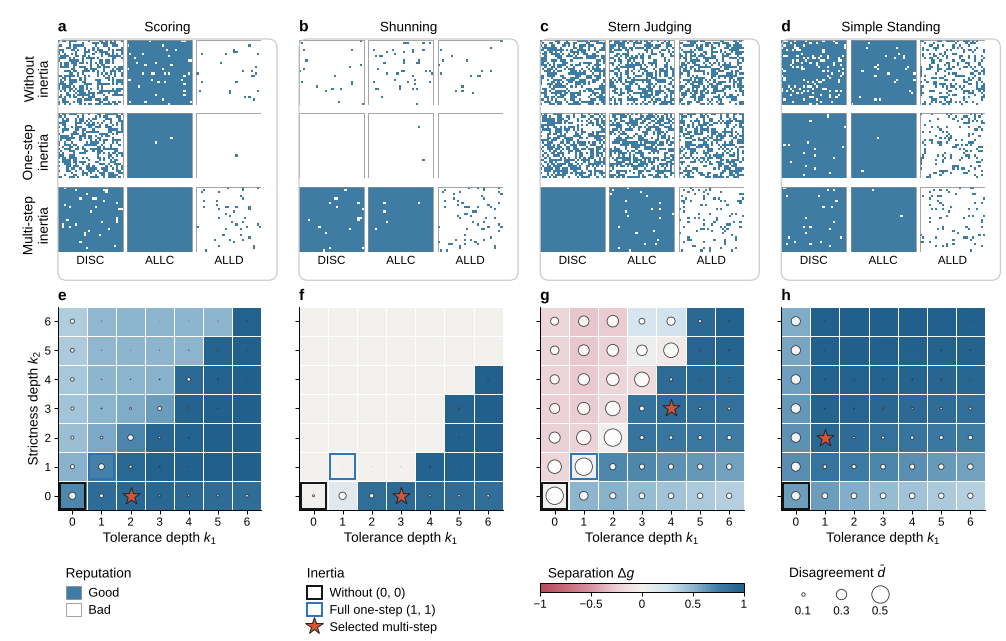

Combined figure: 183 x 114.2 mm.
Saved 24 figures, each in PDF and SVG format.


In [12]:
# Vertical layout (mm from the top edge).
TITLE_BASELINE = 3.6
FRAME_TOP = 5.
ROW_GAP, TARGET_LABEL_SPACE = 1.5, 3.
FRAME_HEIGHT = FRAME_PAD + 3 * MATRIX_HEIGHT + 2 * ROW_GAP + TARGET_LABEL_SPACE + 1.
DEPTH_TOP = FRAME_TOP + FRAME_HEIGHT + 6.
KEY_HEADING = DEPTH_TOP + DEPTH_SIZE + 11.     # baseline of the four key headings
KEY_BODY = KEY_HEADING + 1.5                   # top of the key contents
KEY_BAR_HEIGHT = 1.8                           # colour bar thickness; bubbles are centred on it
FIGURE_HEIGHT = KEY_BODY + 10.

figure = plt.figure(figsize=(FIGURE_WIDTH * MM, FIGURE_HEIGHT * MM))
to_mm = mm_transform(figure)


def add_axes_mm(x, top, width, height):
    return figure.add_axes([x / FIGURE_WIDTH, 1 - (top + height) / FIGURE_HEIGHT, width / FIGURE_WIDTH, height / FIGURE_HEIGHT])


def text_mm(x, top, string, **kwargs):
    figure.text(x, FIGURE_HEIGHT - top, string, transform=to_mm, **kwargs)


def column_left(column):
    """Left edge of the panels in a column (mm)."""
    return LEFT + column * (COLUMN_WIDTH + COLUMN_GAP) + FRAME_PAD


for column, norm in enumerate(NORMS):
    x0 = LEFT + column * (COLUMN_WIDTH + COLUMN_GAP)
    figure.patches.append(FancyBboxPatch((x0, FIGURE_HEIGHT - FRAME_TOP - FRAME_HEIGHT), COLUMN_WIDTH, FRAME_HEIGHT,
        boxstyle="round,pad=0,rounding_size=1.6", facecolor="none", edgecolor=FRAME_EDGE, linewidth=.6, transform=to_mm))
    panel_label(figure, x0, FIGURE_HEIGHT - TITLE_BASELINE, chr(97 + column))
    text_mm(x0 + COLUMN_WIDTH / 2, TITLE_BASELINE, NORM_NAMES[norm], ha="center", va="baseline", fontsize=7)
    for row, regime in enumerate(REGIMES):
        top = FRAME_TOP + FRAME_PAD + row * (MATRIX_HEIGHT + ROW_GAP)
        axis = add_axes_mm(x0 + FRAME_PAD, top, PANEL_WIDTH, MATRIX_HEIGHT)
        draw_matrix(axis, matrices[norm, regime], show_targets=(regime == REGIMES[-1]))
        if column == 0:
            text_mm(LEFT - 4., top + MATRIX_HEIGHT / 2, ROW_LABELS[regime], rotation=90, ha="center", va="center",
                fontsize=7, linespacing=1.1, multialignment="center")

    axis = add_axes_mm(x0 + FRAME_PAD, DEPTH_TOP, DEPTH_SIZE, DEPTH_SIZE)
    image = draw_depth(axis, norm)
    axis.set_xlabel(r"Tolerance depth $k_1$")
    if column == 0:
        axis.set_ylabel(r"Strictness depth $k_2$")
    else:
        axis.tick_params(labelleft=False)
    panel_label(figure, x0, FIGURE_HEIGHT - DEPTH_TOP + 2.4, chr(101 + column))

# Key: four groups, each aligned with one panel column, with headings on a shared baseline.
# All headings are typeset as mathtext so plain and mathematical headings share one baseline.
for column, heading in enumerate((r"$\mathrm{Reputation}$", r"$\mathrm{Inertia}$", r"$\mathrm{Separation}\ \Delta g$",
                                  r"$\mathrm{Disagreement}\ \bar{d}$")):
    text_mm(column_left(column), KEY_HEADING, heading, ha="left", va="baseline", fontsize=7)


def key_entries(column, handles):
    figure.legend(handles=handles, loc="upper left", bbox_to_anchor=(column_left(column), FIGURE_HEIGHT - KEY_BODY),
        bbox_transform=to_mm, ncol=1, handlelength=1.2, handleheight=1.2, handletextpad=.6, labelspacing=.3,
        borderpad=0., borderaxespad=0.)


key_entries(0, [Patch(facecolor=GOOD_COLOR, edgecolor=MATRIX_EDGE, linewidth=.4, label="Good"),
                Patch(facecolor=BAD_COLOR, edgecolor=MATRIX_EDGE, linewidth=.4, label="Bad")])
key_entries(1, [Patch(facecolor="none", edgecolor=REFERENCE_STYLE[regime]["color"], linewidth=BOX_WIDTH,
                      label=REFERENCE_STYLE[regime]["label"]) for regime in ("without_inertia", "one_step")]
               + [Line2D([], [], marker="*", linestyle="none", markersize=np.sqrt(STAR_AREA),
                         markerfacecolor=REFERENCE_STYLE["multi_step"]["color"], markeredgecolor=REFERENCE_STYLE["multi_step"]["edge"],
                         markeredgewidth=.5, label=REFERENCE_STYLE["multi_step"]["label"])])

# Separation: colour bar spanning the panel width, values underneath.
bar_top = KEY_BODY + .6
colorbar_axis = add_axes_mm(column_left(2), bar_top, PANEL_WIDTH, KEY_BAR_HEIGHT)
colorbar = figure.colorbar(image, cax=colorbar_axis, orientation="horizontal", ticks=SEPARATION_TICKS)
colorbar.ax.set_xticklabels(["−1", "−0.5", "0", "0.5", "1"])
colorbar.outline.set_linewidth(.5)

# Disagreement: three bubbles centred on the colour-bar line, values underneath at the colour-bar label height.
value_top = bar_top + KEY_BAR_HEIGHT + (plt.rcParams["xtick.major.size"] + plt.rcParams["xtick.major.pad"]) / 72 * 25.4
bubble_x = [column_left(3) + 2.5 + 7. * i for i in range(len(BUBBLE_VALUES))]
for x, value in zip(bubble_x, BUBBLE_VALUES):
    figure.add_artist(Line2D([x], [FIGURE_HEIGHT - bar_top - KEY_BAR_HEIGHT / 2], transform=to_mm, linestyle="none",
        marker="o", markersize=np.sqrt(bubble_area(value)), markerfacecolor="white", markeredgecolor=INK, markeredgewidth=.4))
    text_mm(x, value_top, f"{value:.1f}", ha="center", va="top", fontsize=6)

save_figure(figure, "Figure2_combined", tight=False)
plt.show()
print(f"Combined figure: {FIGURE_WIDTH:.0f} x {FIGURE_HEIGHT:.1f} mm.")

expected_names = ([f"matrix_{norm}_{regime}" for norm in NORMS for regime in REGIMES] + [f"depth_{norm}" for norm in NORMS]
    + ["key_good", "key_bad", "key_without_inertia", "key_one_step", "key_multi_step", "key_disagreement", "key_separation"]
    + ["Figure2_combined"])
assert all((FIGURES / f"{name}.{extension}").is_file() for name in expected_names for extension in ("pdf", "svg"))
print(f"Saved {len(expected_names)} figures, each in PDF and SVG format.")
